# Spatial transfer — held-out interior tile T4

The **`spatial_transfer1`** model (final transfer recipe: high_weight=0, non-negativity kept, 12 levels)
was trained on the surrounding tiles and **never saw the T4 tile** `[200:400, 200:400]`.
Below: per-layer metrics on the unseen tile, then three example snapshots (best of each episode)
in the paper composite format — per-level **truth | prediction** with one shared colour scale per level.

In [1]:
import sys; sys.path.insert(0,'../../src')
import numpy as np, torch, matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import FuncFormatter
from pathlib import Path
from dataloader import PALMDatasetV2
from model import UNet3DFiLM
OUT=Path('../../outputs'); device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
hf={'london_cm20190720-23':set(range(1,25)),'london_cm20190820-23':set(range(25,49)),'london_cm20190904-07':set(range(49,73))}
ZH=[15,25,35,45,55,75,95,115,135,155,175,195]; NZ=12; TILE=(200,400,200,400)
RUN='spatial_transfer1_mask'; CMAP='viridis'; WIDEN=0.5   # widen shared scale on z>=5 (paper convention)
ds=PALMDatasetV2(mask_input=True, normalise=True,roi=TILE,hour_filter=hf,global_pm_norm=False,em_bg_norm=True,t_hist=1,z_range=(0,NZ))
ck=torch.load(OUT/RUN/'checkpoints'/'best.pt',map_location='cpu',weights_only=False)
model=UNet3DFiLM(in_ch=19,spatial_ch=3,base_ch=16,dropout=0.0,n_z=NZ,use_attention=True,n_down=3)
model.load_state_dict(ck['model_state_dict']); model.to(device).eval()
st=ck['norm_stats']; ds._stats=st
mean=torch.tensor(st['pm25']['mean'][:NZ]).view(-1,1,1); std=torch.tensor(st['pm25']['std'][:NZ]).view(-1,1,1)
print('T4 test samples',len(ds))

# Figure font consistent with main text (Times New Roman; Liberation Serif is a
# metric-compatible fallback when Times New Roman is not installed).
import matplotlib as _mpl
_mpl.rcParams.update({'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Liberation Serif', 'Nimbus Roman', 'DejaVu Serif'],
    'mathtext.fontset': 'stix', 'axes.unicode_minus': False, 'font.size': 12})

T4 test samples 72


In [2]:
# per-layer + pooled performance on the unseen T4 tile
def pc(a,b):
    am=a-a.mean();bm=b-b.mean();d=np.sqrt((am**2).sum()*(bm**2).sum())
    return float((am*bm).sum()/d) if d>1e-9 else np.nan
agg={z:{'r':[],'p':[],'s':[]} for z in range(NZ)}
ssr=np.zeros(NZ); cnt=np.zeros(NZ); snap_r=np.full(len(ds),np.nan)
with torch.no_grad():
    for i in range(len(ds)):
        x,y,mk=ds[i]; t=torch.expm1(y*std+mean).numpy(); msk=mk.numpy().astype(bool)
        p=torch.expm1(model(x.unsqueeze(0).to(device)).cpu()[0]*std+mean).numpy()
        rs=[]
        for z in range(NZ):
            s=msk[z]; a=t[z][s].astype(np.float64); b=p[z][s].astype(np.float64)
            if a.size<10 or a.std()<1e-6: continue
            ssr[z]+=((b-a)**2).sum(); cnt[z]+=a.size
            agg[z]['r'].append(np.sqrt(np.mean((b-a)**2))); r=pc(a,b); agg[z]['p'].append(r); agg[z]['s'].append(b.std()/a.std()); rs.append(r)
        snap_r[i]=np.mean(rs) if rs else np.nan
mn=lambda l:np.mean(l) if l else np.nan
print(f'{"height":>8}{"RMSE":>9}{"r":>8}{"sigma":>8}   (transfer model, unseen T4 tile)')
print('-'*40)
for z in range(NZ):
    a=agg[z]; print(f'{ZH[z]:>6}m {mn(a["r"]):>9.3f}{mn(a["p"]):>8.3f}{mn(a["s"]):>8.2f}')
PP=[x for z in range(NZ) for x in agg[z]['p']]
print(f'\nz0-11 overall: pooled RMSE {np.sqrt(ssr.sum()/cnt.sum()):.3f}   mean r {np.mean(PP):.3f}')
# best snapshot of each episode (Jul: 0-23, Aug: 24-47, Sep: 48-71)
CASES=[(56,'idx56  6 Sep 2019 09:00 (morning, best)'),(59,'idx59  6 Sep 2019 12:00 (noon)'),(39,'idx39  21 Aug 2019 16:00 (afternoon, hardest)')]
print('cases:',CASES)

  height     RMSE       r   sigma   (transfer model, unseen T4 tile)
----------------------------------------
    15m       nan     nan     nan
    25m     1.014   0.523    0.77
    35m     0.854   0.633    0.80
    45m     0.769   0.616    0.87
    55m     0.683   0.563    0.74
    75m     0.512   0.544    0.60
    95m     0.422   0.511    0.55
   115m     0.361   0.490    0.56
   135m     0.332   0.472    0.64
   155m     0.353   0.431    0.68
   175m     0.351   0.372    0.69
   195m     0.357   0.306    0.61

z0-11 overall: pooled RMSE 0.554   mean r 0.496
cases: [(56, 'idx56  6 Sep 2019 09:00 (morning, best)'), (59, 'idx59  6 Sep 2019 12:00 (noon)'), (39, 'idx39  21 Aug 2019 16:00 (afternoon, hardest)')]


## Climatology baseline

The held-out tile's **own per-cell temporal mean over the training hours** (test hours excluded). A strong reference: unlike the transfer model it has access to the target tile's history. Same metrics as above.

In [3]:
SIMH={'london_cm20190720-23':96,'london_cm20190820-23':96,'london_cm20190904-07':144}
hf_tr={s:(set(range(1,SIMH[s]+1)) - hf.get(s,set())) for s in SIMH}
ds_tr=PALMDatasetV2(normalise=True,roi=TILE,hour_filter=hf_tr,global_pm_norm=False,em_bg_norm=True,t_hist=1,z_range=(0,NZ)); ds_tr._stats=st
ssum=scnt=None
for i in range(len(ds_tr)):
    _,y,mk=ds_tr[i]; tp=torch.expm1(y*std+mean).numpy(); m=mk.numpy().astype(bool)
    if ssum is None: ssum=np.zeros_like(tp); scnt=np.zeros_like(tp)
    ssum+=np.where(m,tp,0.0); scnt+=m
clim=ssum/np.maximum(scnt,1)   # per-cell temporal mean
ssr_c=np.zeros(NZ); cnt_c=np.zeros(NZ); rc=[]
for i in range(len(ds)):
    _,y,mk=ds[i]; t=torch.expm1(y*std+mean).numpy(); m=mk.numpy().astype(bool)
    for z in range(NZ):
        s=m[z]; a=t[z][s].astype(np.float64); b=clim[z][s].astype(np.float64)
        if a.size<10 or a.std()<1e-6: continue
        ssr_c[z]+=((b-a)**2).sum(); cnt_c[z]+=a.size; rc.append(pc(a,b))
rmse_clim=np.sqrt(ssr_c.sum()/cnt_c.sum()); r_clim=np.mean(rc)
rmse_mod=np.sqrt(ssr.sum()/cnt.sum()); r_mod=np.mean([x for z in range(NZ) for x in agg[z]['p']])
print(f'{"":26}{"RMSE":>8}{"r":>8}'); print('-'*42)
print(f'{"Climatology":26}{rmse_clim:>8.3f}{r_clim:>8.3f}')
print(f'{"UNet3DFiLM (this work)":26}{rmse_mod:>8.3f}{r_mod:>8.3f}')

                              RMSE       r
------------------------------------------
Climatology                  2.746   0.430
UNet3DFiLM (this work)       0.554   0.496


In [4]:
# per level: PALM (reference) | prediction | relative error (%). 2 levels per row -> 6 panels per row.
def plot_case(si):
    x,y,mk=ds[si]; mask=mk.numpy().astype(bool)
    with torch.no_grad(): out=model(x.unsqueeze(0).to(device)).cpu()[0]
    truth=torch.expm1(y*std+mean).numpy(); pred=torch.expm1(out*std+mean).numpy()
    rel=100.0*(pred-truth)/np.where(truth>1e-6,truth,np.nan)
    levels=list(range(NZ)); npr=2; nrows=(len(levels)+npr-1)//npr
    # per level block: truth, pred, shared-cbar, spacer, err, err-cbar ; big gap between blocks
    wr=[]; blocks=[]; ci=0
    for L in range(npr):
        blocks.append((ci,ci+1,ci+2,ci+4,ci+5)); wr+=[1,1,0.06,0.16,1,0.06]; ci+=6
        if L<npr-1: wr+=[0.38]; ci+=1
    fig=plt.figure(figsize=(14,2.35*nrows))
    gs=GridSpec(nrows,len(wr),width_ratios=wr,wspace=0.05,hspace=0.28)
    for i,z in enumerate(levels):
        r=i//npr; L=i%npr; ct,cp,cc1,ce,cc2=blocks[L]
        axt=fig.add_subplot(gs[r,ct]); axp=fig.add_subplot(gs[r,cp]); axc1=fig.add_subplot(gs[r,cc1])
        axe=fig.add_subplot(gs[r,ce]); axc2=fig.add_subplot(gs[r,cc2])
        ti=np.where(mask[z],truth[z],np.nan); pi=np.where(mask[z],pred[z],np.nan); ei=np.where(mask[z],rel[z],np.nan)
        if mask[z].sum()>=10:
            a=truth[z][mask[z]]; b=pred[z][mask[z]]
            vmin=min(np.percentile(a,1),np.percentile(b,1)); vmax=max(np.percentile(a,99),np.percentile(b,99))
            if z>=5 and WIDEN>0: s=vmax-vmin; vmin-=WIDEN*s; vmax+=WIDEN*s
            el=np.nanpercentile(np.abs(ei),98)+1e-9
        else: vmin,vmax,el=0.0,1.0,1.0
        imt=axt.imshow(ti,cmap=CMAP,vmin=vmin,vmax=vmax,origin='lower')
        axp.imshow(pi,cmap=CMAP,vmin=vmin,vmax=vmax,origin='lower')
        ime=axe.imshow(ei,cmap='RdBu_r',vmin=-el,vmax=el,origin='lower')
        for ax in (axt,axp,axe): ax.set_xticks([]); ax.set_yticks([])
        axt.set_title(f'{ZH[z]}m PALM',fontsize=11); axp.set_title(f'{ZH[z]}m pred',fontsize=11); axe.set_title(f'{ZH[z]}m diff',fontsize=11)
        plt.colorbar(imt,cax=axc1)
        cb=plt.colorbar(ime,cax=axc2); cb.ax.yaxis.set_major_formatter(FuncFormatter(lambda v,p: f'{v:+.0f}%'))
        axc1.tick_params(labelsize=9.5); axc2.tick_params(labelsize=9.5)
    import os; os.makedirs('figs', exist_ok=True)
    fig.savefig(f'figs/{RUN}_idx{si}.png', dpi=300, bbox_inches='tight')
    plt.show()
print('ready')

ready


### idx56 — 6 Sep 2019 09:00 (morning, best transfer case)

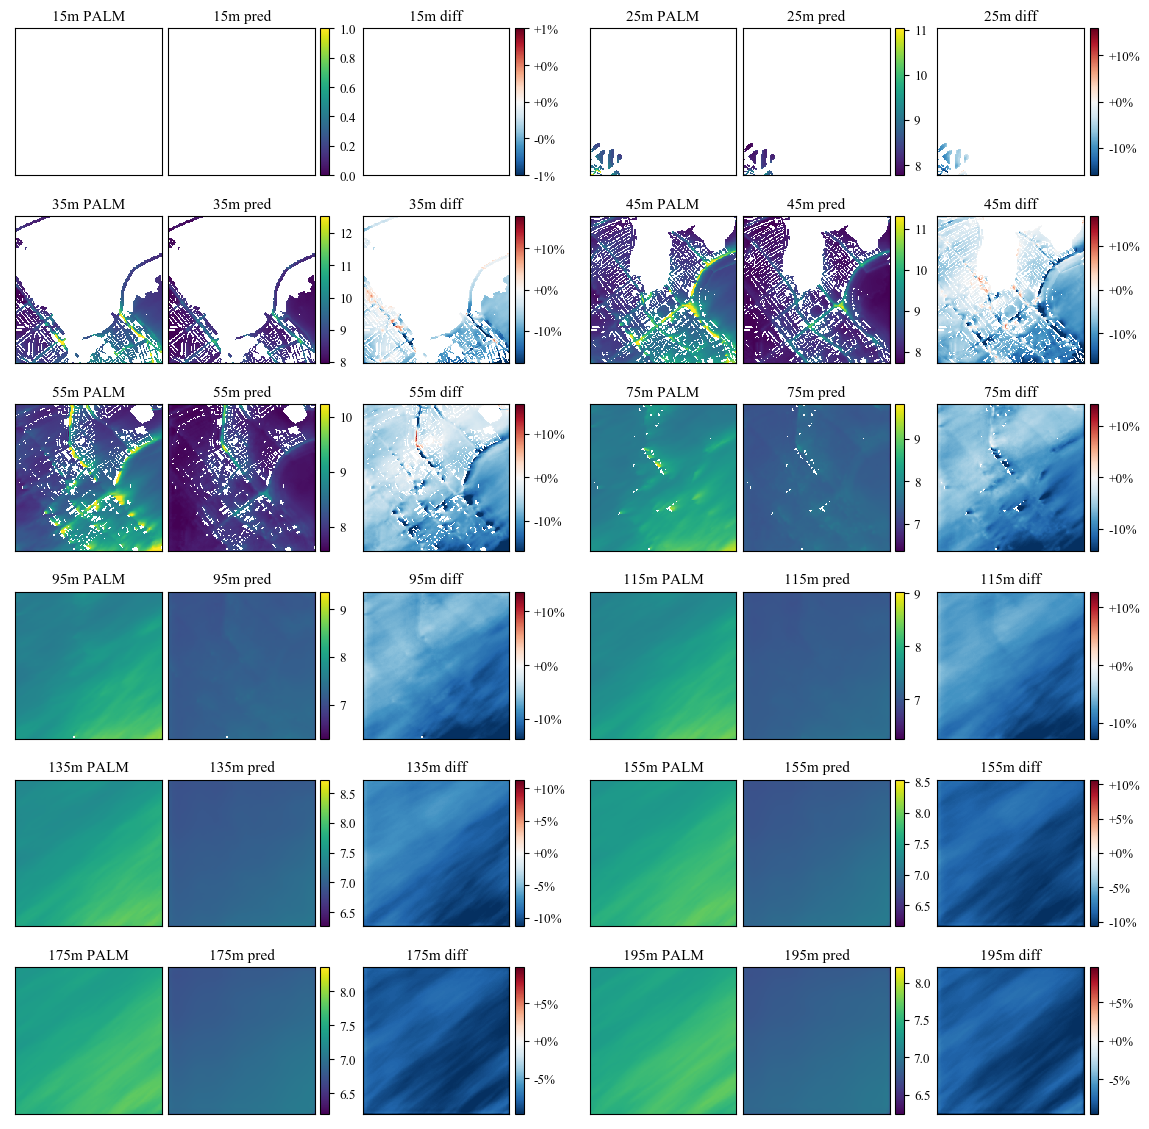

In [5]:
plot_case(56)

### idx59 — 6 Sep 2019 12:00 (noon)

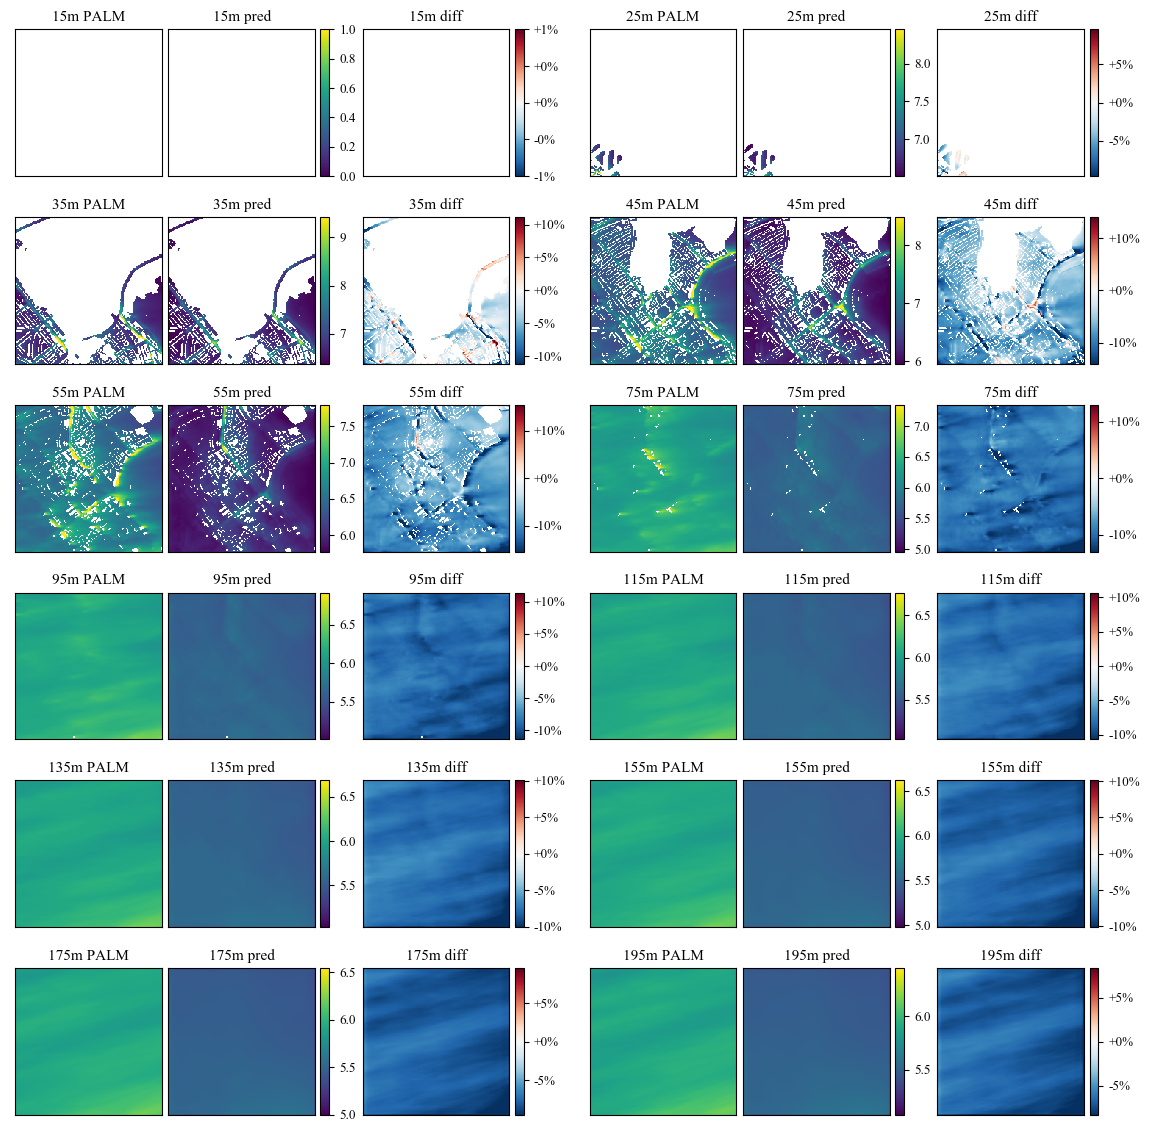

In [6]:
plot_case(59)

### idx39 — 21 Aug 2019 16:00 (afternoon, hardest)

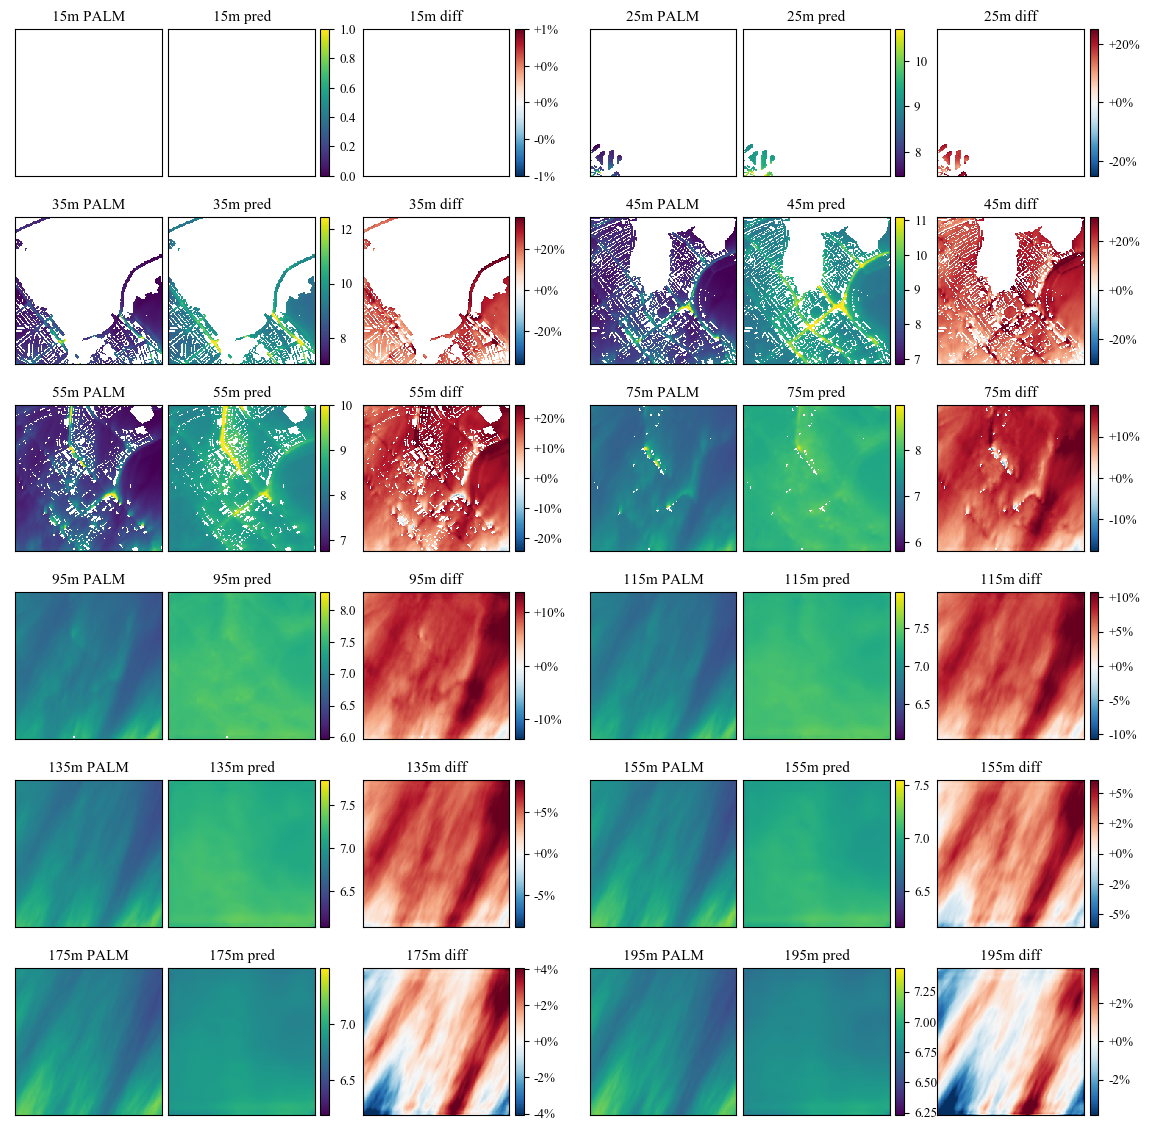

In [7]:
plot_case(39)

## Best test case - results layout, per-level r & RMSE (all levels, new)

best test sample: idx=56  mean r=0.834


saved figs/spatial_transfer1_mask_best_results_all.png


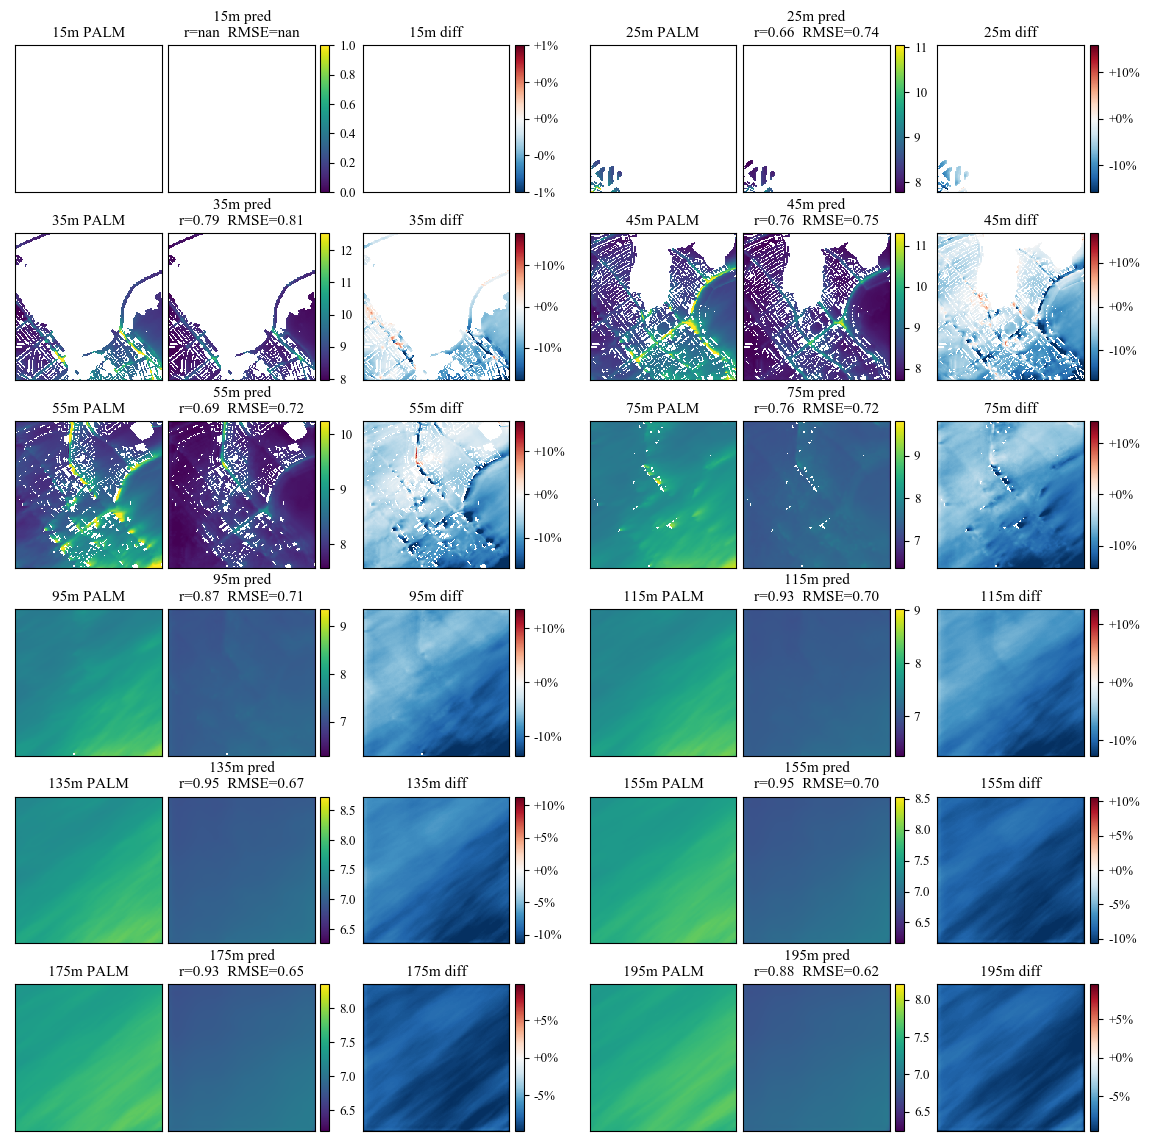

In [8]:
# Best test case in OLD results layout ("{ZH}m PALM/pred/diff", WIDEN on z>=5) + per-level r & RMSE on pred
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import FuncFormatter
def _pc(a,b):
    am=a-a.mean();bm=b-b.mean();d=np.sqrt((am**2).sum()*(bm**2).sum())
    return float((am*bm).sum()/d) if d>1e-9 else np.nan
_bi=-1; _br=-1
with torch.no_grad():
    for _i in range(len(ds)):
        _x,_y,_mk=ds[_i]; _mm=_mk.numpy().astype(bool)
        _t=torch.expm1(_y*std+mean).numpy(); _p=torch.expm1(model(_x.unsqueeze(0).to(device)).cpu()[0]*std+mean).numpy()
        _rs=[_pc(_t[z][_mm[z]].astype(float),_p[z][_mm[z]].astype(float)) for z in range(NZ) if _mm[z].sum()>10]
        _mr=float(np.nanmean(_rs)) if _rs else -1
        if _mr>_br: _br=_mr; _bi=_i
print(f'best test sample: idx={_bi}  mean r={_br:.3f}')
WIDEN=0.5
def plot_best_new(si, fname):
    x,y,mk=ds[si]; mask=mk.numpy().astype(bool)
    with torch.no_grad(): out=model(x.unsqueeze(0).to(device)).cpu()[0]
    truth=torch.expm1(y*std+mean).numpy(); pred=torch.expm1(out*std+mean).numpy()
    rel=100.0*(pred-truth)/np.where(truth>1e-6,truth,np.nan)
    levels=list(range(NZ)); npr=2; nrows=(len(levels)+npr-1)//npr
    wr=[]; blocks=[]; ci=0
    for L in range(npr):
        blocks.append((ci,ci+1,ci+2,ci+4,ci+5)); wr+=[1,1,0.06,0.16,1,0.06]; ci+=6
        if L<npr-1: wr+=[0.38]; ci+=1
    fig=plt.figure(figsize=(14,2.35*nrows)); gs=GridSpec(nrows,len(wr),width_ratios=wr,wspace=0.05,hspace=0.28)
    for i,z in enumerate(levels):
        rw=i//npr; L=i%npr; ct,cp,cc1,ce,cc2=blocks[L]
        axt=fig.add_subplot(gs[rw,ct]); axp=fig.add_subplot(gs[rw,cp]); axc1=fig.add_subplot(gs[rw,cc1])
        axe=fig.add_subplot(gs[rw,ce]); axc2=fig.add_subplot(gs[rw,cc2])
        ti=np.where(mask[z],truth[z],np.nan); pi=np.where(mask[z],pred[z],np.nan); ei=np.where(mask[z],rel[z],np.nan)
        if mask[z].sum()>=10:
            a=truth[z][mask[z]].astype(float); b=pred[z][mask[z]].astype(float)
            r=_pc(a,b); rm=float(np.sqrt(np.mean((b-a)**2)))
            vmin=min(np.percentile(a,1),np.percentile(b,1)); vmax=max(np.percentile(a,99),np.percentile(b,99))
            if z>=5 and WIDEN>0: s=vmax-vmin; vmin-=WIDEN*s; vmax+=WIDEN*s
            el=np.nanpercentile(np.abs(ei),98)+1e-9
        else: r,rm,vmin,vmax,el=np.nan,np.nan,0.0,1.0,1.0
        imt=axt.imshow(ti,cmap='viridis',vmin=vmin,vmax=vmax,origin='lower')
        axp.imshow(pi,cmap='viridis',vmin=vmin,vmax=vmax,origin='lower')
        ime=axe.imshow(ei,cmap='RdBu_r',vmin=-el,vmax=el,origin='lower')
        for ax in (axt,axp,axe): ax.set_xticks([]); ax.set_yticks([])
        axt.set_title(f'{ZH[z]}m PALM',fontsize=11)
        axp.set_title(f'{ZH[z]}m pred\nr={r:.2f}  RMSE={rm:.2f}',fontsize=11)
        axe.set_title(f'{ZH[z]}m diff',fontsize=11)
        fig.colorbar(imt,cax=axc1)
        cb=fig.colorbar(ime,cax=axc2); cb.ax.yaxis.set_major_formatter(FuncFormatter(lambda v,p: f'{v:+.0f}%'))
        axc1.tick_params(labelsize=9.5); axc2.tick_params(labelsize=9.5)
    import os; os.makedirs('figs',exist_ok=True)
    fig.savefig('figs/'+fname,dpi=300,bbox_inches='tight'); print('saved figs/'+fname); plt.show()
plot_best_new(_bi, f'{RUN}_best_results_all.png')